## 11-Нейрондық желілер және Deep Learning негіздері

**Міндеттері:**

- MNIST қолжазба цифрларының деректерін жүктеу;
- қарапайым нейрондық желі құру;
- модельді оқыту;
- тест деректерімен тексеру;
- модельдің дәлдігін бағалау

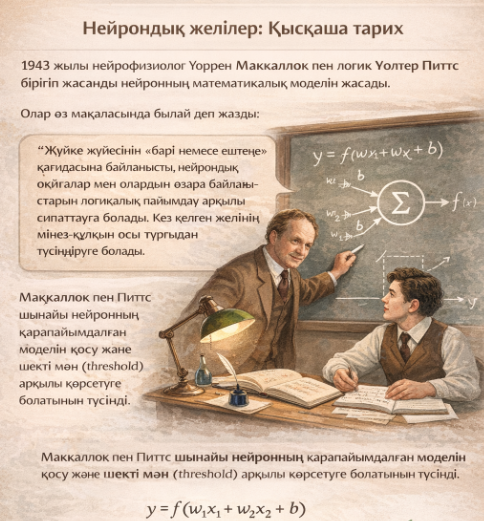



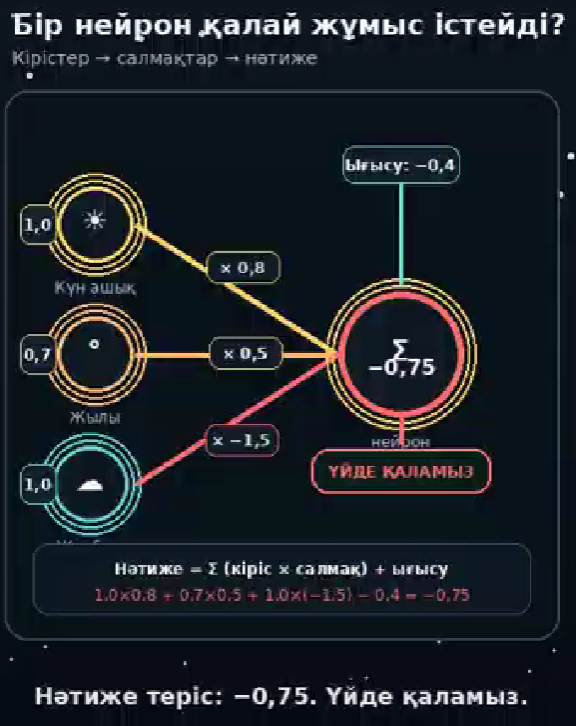

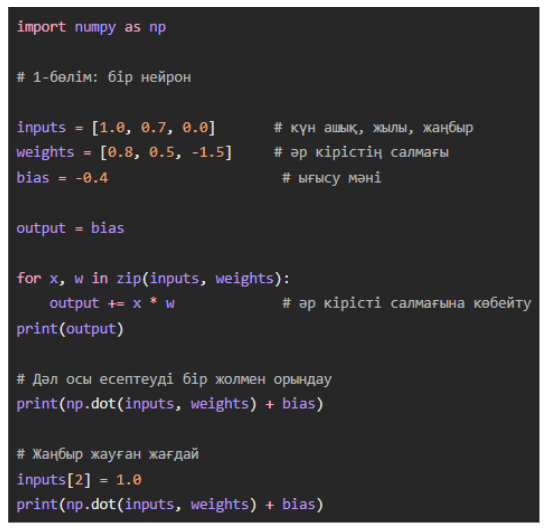

## 1 TensorFlow орнатамыз

In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2 [MNIST деректер жиынтығын](http://yann.lecun.com/exdb/mnist/) жүктеп, алдын ала дайындаңыз. Деректерді бүтін сандар форматынан жылжымалы нүктелі сандар (`float`) форматына түрлендіріңіз:

In [2]:
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 3 Машиналық оқыту моделін құру

Қабаттарды бірінен кейін бірін орналастыру арқылы [**`tf.keras.Sequential`**](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential?hl=ru) моделін құрыңыз.

In [3]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Әрбір мысал үшін модель әр класқа тиесілілікті көрсететін сандық бағалар векторын қайтарады. Бұл бағалар **логиттер** немесе **логарифмдік ықтималдықтар** деп аталады.

In [4]:
predictions = model(x_train[:1]).numpy()
predictions

array([[-0.18415377,  0.4375189 ,  0.8155195 , -0.15066122,  0.04601942,
         0.11087453,  0.62498146,  0.722809  ,  0.20081717, -0.5645153 ]],
      dtype=float32)

## 4 [**`tf.nn.softmax`**](https://www.tensorflow.org/api_docs/python/tf/nn/softmax?hl=ru) функциясы осы логиттерді әр класқа тиесілі **ықтималдық мәндеріне** түрлендіреді:

In [5]:
tf.nn.softmax(predictions).numpy()

array([[0.06214494, 0.11571635, 0.16887227, 0.06426158, 0.07822917,
        0.08347087, 0.13957535, 0.15391988, 0.09132643, 0.04248316]],
      dtype=float32)

### Ескерту. `tf.nn.softmax` функциясын нейрондық желінің соңғы қабатындағы белсендіру функциясы ретінде бірден қолдануға болады. Бұл модель нәтижесін түсінуді жеңілдетеді. Алайда оны соңғы қабатқа тікелей қосу ұсынылмайды, өйткені кейбір жағдайларда шығын мәні дәл әрі сандық тұрғыдан тұрақты есептелмеуі мүмкін.

## 5 Модельді оқыту үшін `losses.SparseCategoricalCrossentropy` шығын функциясын анықтаңыз. Бұл функция модель шығарған логиттер векторын және дұрыс кластың индексін қабылдап, әрбір мысал бойынша бір шығын мәнін есептейді.

In [6]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

 Бұл шығын дұрыс кластың ықтималдығының теріс логарифміне тең. Егер модель дұрыс класты толық сенімділікпен анықтаса, шығын мәні нөлге тең болады.

Әзірге оқытылмаған модель әр классқа кездейсоққа жуық ықтималдық береді: 10 кластың әрқайсысына шамамен **1/10**. Сондықтан бастапқы шығын мәні **`-tf.math.log(1/10) ≈ 2.3`** шамасында болуы керек.

In [7]:
loss_fn(y_train[:1], predictions).numpy()

np.float32(2.4832578)

#### Модельді оқытуды бастамас бұрын оны [**`Model.compile`**](https://www.tensorflow.org/api_docs/python/tf/keras/Model?hl=ru#compile) әдісі арқылы баптап, компиляциялаңыз.

**Ол үшін:**

- `optimizer` параметріне `adam` оптимизаторын;
- `loss` параметріне бұған дейін анықталған `loss_fn` шығын функциясын;
- `metrics` параметріне модельдің дұрыс болжау үлесін есептейтін
- `accuracy` метрикасын орнатыңыз.

In [8]:
model.compile(optimizer='adam',
              loss=loss_fn,
              metrics=['accuracy'])

## 6 Модельді оқытыңыз және бағалаңыз

Модель параметрлерін баптап, шығын мәнін азайту үшін [**`Model.fit`**](https://www.tensorflow.org/api_docs/python/tf/keras/Model?hl=ru#fit) әдісін қолданыңыз:

In [9]:
model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9133 - loss: 0.2958
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9576 - loss: 0.1429
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9673 - loss: 0.1067
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9729 - loss: 0.0889
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9766 - loss: 0.0745


### 7 [**`Model.evaluate`**](https://www.tensorflow.org/api_docs/python/tf/keras/Model?hl=ru#evaluate) әдісі модельдің жұмыс сапасын тексереді. Әдетте модель **валидациялық деректер жиынында (Validation set)** немесе **тестілік деректер жиынында (Test set)** бағаланады.

In [10]:
model.evaluate(x_test,  y_test, verbose=2)

313/313 - 1s - 2ms/step - accuracy: 0.9778 - loss: 0.0751


[0.07511559128761292, 0.9778000116348267]

Енді кескіндерді жіктейтін модель осы деректер жиынында шамамен **98% дәлдікке** жетті. Толығырақ ақпаратты [TensorFlow оқулықтарынан](https://www.tensorflow.org/tutorials/?hl=ru) оқуға болады.

Егер модельдің нәтижені ықтималдық түрінде қайтарғанын қаласаңыз, оқытылған модельге **Softmax қабатын** қосуға болады:

In [11]:
probability_model = tf.keras.Sequential([
  model,
  tf.keras.layers.Softmax()
])

In [12]:
probability_model(x_test[:5])

<tf.Tensor: shape=(5, 10), dtype=float32, numpy=
array([[8.6221199e-09, 2.9070168e-08, 4.7497929e-06, 1.4848569e-04,
        1.5915805e-12, 1.1575364e-06, 5.2314622e-14, 9.9984407e-01,
        1.6116131e-07, 1.2961802e-06],
       [1.7534042e-07, 1.5819847e-03, 9.9840778e-01, 7.4723844e-06,
        1.9984608e-13, 6.4212566e-07, 1.0132921e-06, 4.7214793e-13,
        9.3095639e-07, 3.0438298e-11],
       [6.7334746e-08, 9.9960750e-01, 1.8539205e-05, 2.2365278e-07,
        8.0117552e-06, 8.4144358e-06, 5.0597164e-06, 1.1007370e-04,
        2.4149506e-04, 5.2079002e-07],
       [9.9920517e-01, 2.2682471e-07, 6.6948187e-04, 7.0066280e-06,
        3.0656943e-07, 3.7385325e-06, 1.1210016e-04, 1.8828996e-07,
        5.3147301e-07, 1.0782542e-06],
       [5.8092655e-06, 7.0628126e-09, 5.3475658e-05, 1.6707301e-07,
        9.9437642e-01, 1.0195632e-06, 5.0367244e-06, 7.2215655e-05,
        1.1068468e-06, 5.4847840e-03]], dtype=float32)>

# Тапсырма

MNIST деректер жиынындағы қолжазба цифрларын нейрондық желі арқылы жіктеу

**Мақсаты:** TensorFlow және Keras көмегімен нейрондық желі құру, оқыту және оның сапасын бағалау.

### Тапсырмалар:

1. `TensorFlow` кітапханасын импорттаңыз.
2. `MNIST` деректер жиынын жүктеңіз.
3. Кескін пиксельдерінің мәндерін `0–255` аралығынан `0–1` аралығына келтіріңіз.
4. Оқыту жиынындағы алғашқы 10 кескінді атауларымен бірге көрсетіңіз.
5. `tf.keras.Sequential` көмегімен нейрондық желі құрыңыз:

   - `Flatten` қабаты;
   - 128 нейроннан тұратын `Dense` қабаты және `ReLU`;
   - `Dropout(0.2)` қабаты;
   - 10 нейроннан тұратын шығыс қабаты.

6. Модельді келесі параметрлермен компиляциялаңыз:

   - оптимизатор — `Adam`;
   - шығын функциясы — `SparseCategoricalCrossentropy`;
   - бағалау метрикасы — `accuracy`.

7. Модельді **5 эпоха** бойы оқытыңыз.
8. Модельді тестілік деректер жиынында бағалаңыз.
9. `Softmax` көмегімен алғашқы 10 тестілік кескіннің класын болжаңыз.
10. Нақты және болжанған цифрларды кескіндермен бірге көрсетіңіз.
11. Модель қате таныған кемінде 5 кескінді тауып, көрсетіңіз.
12. Қорытынды жазыңыз:

   - модель қандай дәлдік көрсетті?
   - қандай цифрларды жиі шатастырды?
   - модельдің сапасын қалай жақсартуға болады?

## Қосымша тапсырмалар:

- 1) Жасырын қабаттағы нейрондар санын `128`-ден `256`-ға өзгертіп, модельді қайта оқытыңыз. Екі модельдің дәлдігін салыстырып, нәтижесін кесте түрінде көрсетіңіз.
- 2) Keras Tuner көмегімен жасырын қабаттағы нейрондардың ең тиімді санын және Adam оптимизаторының оқыту жылдамдығын автоматты түрде анықтаңыз. Табылған гиперпараметрлер арқылы модельді қайта оқытып, тестілік деректердегі дәлдігін бағалаңыз және қысқаша қорытынды жазыңыз.

https://www.tensorflow.org/tutorials/keras/keras_tuner?hl=ru
